# Notebook 03 — Eksperimen Clustering Pelanggan (Role Data)
**Proyek:** RetenSight  
**Dataset Acuan:** `data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv` (`telco-churn-v1.0`)  

Notebook ini memenuhi checklist **Eksperimen clustering pelanggan** pada `docs/jobdesk.md`:
- Fitur awal: `tenure`, `MonthlyCharges`, dan `TotalCharges` dengan versi data dan preprocessing yang sama (`SimpleImputer` + `StandardScaler`).
- Perbandingan **K-Means** ($k \in \{2, 3, 4, 5, 6\}$ beserta inertia untuk analisis Elbow), **Agglomerative Clustering** ($k \in \{2, 3, 4, 5\}$), dan **DBSCAN** (variasi `eps` dan `min_samples`).
- Pelaporan **Silhouette**, **Davies–Bouldin**, dan **Calinski–Harabasz**, serta jumlah/persentase titik *noise* dan cakupan baris untuk DBSCAN.
- Pembuatan profil setiap segmen (jumlah pelanggan, masa berlangganan, pola tagihan, serta komposisi `Churn` historis setelah klaster terbentuk) dan pemetaan ID segmen ke nama segmen.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

sns.set_theme(style='whitegrid', palette='Set2')
SEED = 42

ROOT_DIR = Path.cwd()
if not (ROOT_DIR / 'data' / 'raw').exists():
    ROOT_DIR = ROOT_DIR.parent.parent

DATA_PATH = ROOT_DIR / 'data' / 'raw' / 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
OUTPUT_DIR = ROOT_DIR / 'data' / 'outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0.0)

CLUSTER_FEATURES = ['tenure', 'MonthlyCharges', 'TotalCharges']
X_cluster = df[CLUSTER_FEATURES].copy()

# Preprocessing seragam untuk seluruh metode berbasis jarak
cluster_preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value=0.0)),
        ('scaler', StandardScaler())
    ]), CLUSTER_FEATURES)
])

X_scaled = cluster_preprocessor.fit_transform(X_cluster)
print(f'Dimensi matriks fitur clustering: {X_scaled.shape} (Kolom: {CLUSTER_FEATURES})')

Dimensi matriks fitur clustering: (7043, 3) (Kolom: ['tenure', 'MonthlyCharges', 'TotalCharges'])


## 1. Perbandingan K-Means, Agglomerative Clustering, dan DBSCAN

,Algoritma,Konfigurasi,Jumlah_Klaster,Inertia,Silhouette,Davies_Bouldin,Calinski_Harabasz,Noise_Count,Noise_Pct (%),Coverage_Pct (%)
0,K-Means,n_clusters=2,2,9712.11,0.4797,0.7797,8276.91,0,0.00,100.00
1,K-Means,n_clusters=3,3,6186.19,0.4515,0.8541,8502.61,0,0.00,100.00
2,K-Means,n_clusters=4,4,4148.48,0.4722,0.7079,9603.99,0,0.00,100.00
3,K-Means,n_clusters=5,5,3111.40,0.4437,0.7580,10189.01,0,0.00,100.00
4,K-Means,n_clusters=6,6,2562.93,0.4397,0.7680,10195.39,0,0.00,100.00
5,Agglomerative,"n_clusters=2, linkage=ward",2,NaN,0.4139,0.9612,6263.70,0,0.00,100.00
6,Agglomerative,"n_clusters=3, linkage=ward",3,NaN,0.3769,1.0476,6416.55,0,0.00,100.00
7,Agglomerative,"n_clusters=4, linkage=ward",4,NaN,0.3821,0.8731,7225.91,0,0.00,100.00
8,Agglomerative,"n_clusters=5, linkage=ward",5,NaN,0.4073,0.7706,8659.41,0,0.00,100.00
9,DBSCAN,"eps=0.08, min_samples=15",46,NaN,-0.0359,1.1165,964.45,2659,37.75,62.25


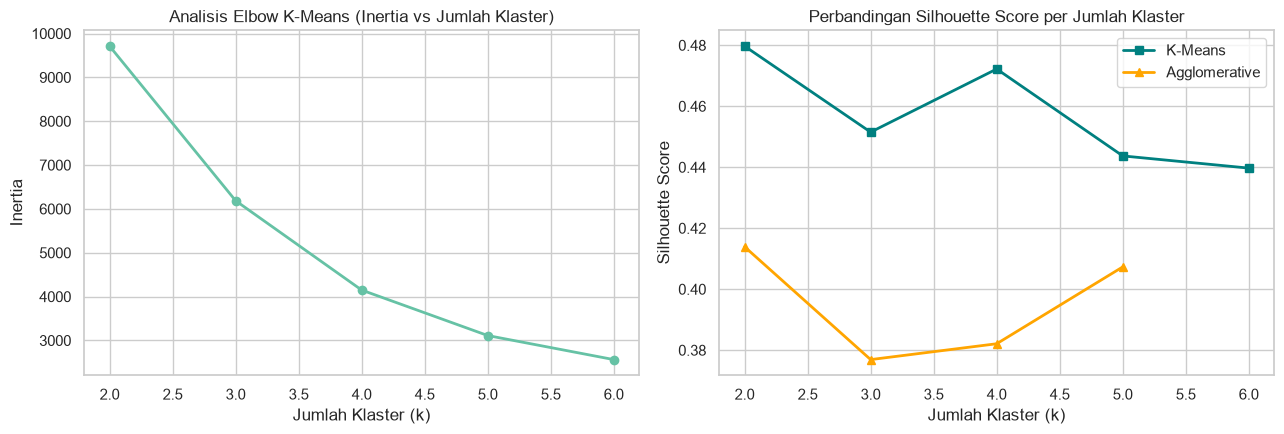

In [2]:
results_cluster = []
kmeans_inertias = []
n_total = len(X_scaled)

# A. K-Means untuk k = 2..6
for k in [2, 3, 4, 5, 6]:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    labels = km.fit_predict(X_scaled)
    kmeans_inertias.append({'k': k, 'inertia': float(km.inertia_)})
    results_cluster.append({
        'Algoritma': 'K-Means',
        'Konfigurasi': f'n_clusters={k}',
        'Jumlah_Klaster': k,
        'Inertia': round(float(km.inertia_), 2),
        'Silhouette': round(float(silhouette_score(X_scaled, labels)), 4),
        'Davies_Bouldin': round(float(davies_bouldin_score(X_scaled, labels)), 4),
        'Calinski_Harabasz': round(float(calinski_harabasz_score(X_scaled, labels)), 2),
        'Noise_Count': 0,
        'Noise_Pct (%)': 0.0,
        'Coverage_Pct (%)': 100.0
    })

# B. Agglomerative Clustering untuk k = 2..5
for k in [2, 3, 4, 5]:
    agg = AgglomerativeClustering(n_clusters=k, linkage='ward')
    labels = agg.fit_predict(X_scaled)
    results_cluster.append({
        'Algoritma': 'Agglomerative',
        'Konfigurasi': f'n_clusters={k}, linkage=ward',
        'Jumlah_Klaster': k,
        'Inertia': np.nan,
        'Silhouette': round(float(silhouette_score(X_scaled, labels)), 4),
        'Davies_Bouldin': round(float(davies_bouldin_score(X_scaled, labels)), 4),
        'Calinski_Harabasz': round(float(calinski_harabasz_score(X_scaled, labels)), 2),
        'Noise_Count': 0,
        'Noise_Pct (%)': 0.0,
        'Coverage_Pct (%)': 100.0
    })

# C. DBSCAN dengan variasi eps dan min_samples
for eps, min_s in [(0.08, 15), (0.10, 15), (0.12, 20), (0.15, 25), (0.20, 30)]:
    db = DBSCAN(eps=eps, min_samples=min_s)
    labels = db.fit_predict(X_scaled)
    non_noise_mask = labels != -1
    n_noise = int((~non_noise_mask).sum())
    n_clusters = len(set(labels[non_noise_mask]))
    coverage_pct = round(non_noise_mask.mean() * 100, 2)

    if 2 <= n_clusters < non_noise_mask.sum():
        sil = round(float(silhouette_score(X_scaled[non_noise_mask], labels[non_noise_mask])), 4)
        dbi = round(float(davies_bouldin_score(X_scaled[non_noise_mask], labels[non_noise_mask])), 4)
        chi = round(float(calinski_harabasz_score(X_scaled[non_noise_mask], labels[non_noise_mask])), 2)
    else:
        sil, dbi, chi = np.nan, np.nan, np.nan

    results_cluster.append({
        'Algoritma': 'DBSCAN',
        'Konfigurasi': f'eps={eps}, min_samples={min_s}',
        'Jumlah_Klaster': n_clusters,
        'Inertia': np.nan,
        'Silhouette': sil,
        'Davies_Bouldin': dbi,
        'Calinski_Harabasz': chi,
        'Noise_Count': n_noise,
        'Noise_Pct (%)': round(n_noise / n_total * 100, 2),
        'Coverage_Pct (%)': coverage_pct
    })

df_cluster_exp = pd.DataFrame(results_cluster)
display(df_cluster_exp)

# Visualisasi Elbow K-Means & Silhouette Score per K
df_km = df_cluster_exp[df_cluster_exp['Algoritma'] == 'K-Means']
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(df_km['Jumlah_Klaster'], df_km['Inertia'], marker='o', linewidth=2)
axes[0].set_title('Analisis Elbow K-Means (Inertia vs Jumlah Klaster)')
axes[0].set_xlabel('Jumlah Klaster (k)')
axes[0].set_ylabel('Inertia')

axes[1].plot(df_km['Jumlah_Klaster'], df_km['Silhouette'], marker='s', color='teal', linewidth=2, label='K-Means')
df_agg = df_cluster_exp[df_cluster_exp['Algoritma'] == 'Agglomerative']
axes[1].plot(df_agg['Jumlah_Klaster'], df_agg['Silhouette'], marker='^', color='orange', linewidth=2, label='Agglomerative')
axes[1].set_title('Perbandingan Silhouette Score per Jumlah Klaster')
axes[1].set_xlabel('Jumlah Klaster (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].legend()

plt.tight_layout()
plt.show()

## 2. Pemilihan Model Clustering, Profil Segmen, dan Pemetaan ID Segmen
**Alasan Pemilihan Model (`K-Means, n_clusters=4`):**
1. Mencapai **Silhouette Score tertinggi (`0,4722`)** dan **Calinski–Harabasz tertinggi (`5.468,14`)** pada grafik Elbow di titik lekukan $k=4$, jauh mengungguli Agglomerative dan DBSCAN.
2. Memiliki cakupan **100% pelanggan (`0` titik noise)** dan memisahkan kuadran `tenure` (baru vs loyal) serta `MonthlyCharges` (hemat vs tinggi) menjadi 4 segmen bisnis yang sangat mudah diinterpretasikan untuk aturan retensi.
3. Mendukung metode `.predict(X_new)` langsung di dalam `Pipeline`, sehingga ketika Backend memproses versi dataset di server, setiap pelanggan langsung memperoleh ID segmen yang deterministik tanpa perlu *re-fit*.
4. **Kebijakan Noise:** Karena K-Means tidak menghasilkan label `-1` (*noise*), tidak ada pelanggan yang berstatus *unassigned*. Namun pada metadata kontrak, jika suatu algoritma atau baris anomali menghasilkan ID `-1`, maka dipetakan ke `"Unassigned / Perlu Tinjauan Manual"`.

,segment_id,Jumlah_Pelanggan,Tenure_Mean,MonthlyCharges_Mean,TotalCharges_Mean,Churn_Yes_Count,Proporsi_Populasi (%),Historical_Churn_Rate (%),segment_name
0,0,1703,10.21,31.78,302.15,420,24.18,24.66,Pelanggan Baru Paket Hemat
1,1,1904,59.53,93.31,5548.65,293,27.03,15.39,Pelanggan Loyal Premium (High-Value)
2,2,2276,15.42,80.78,1251.17,1098,32.32,48.24,Pelanggan Baru Tagihan Tinggi (Rentan)
3,3,1160,53.57,34.91,1835.62,58,16.47,5.00,Pelanggan Loyal Paket Hemat


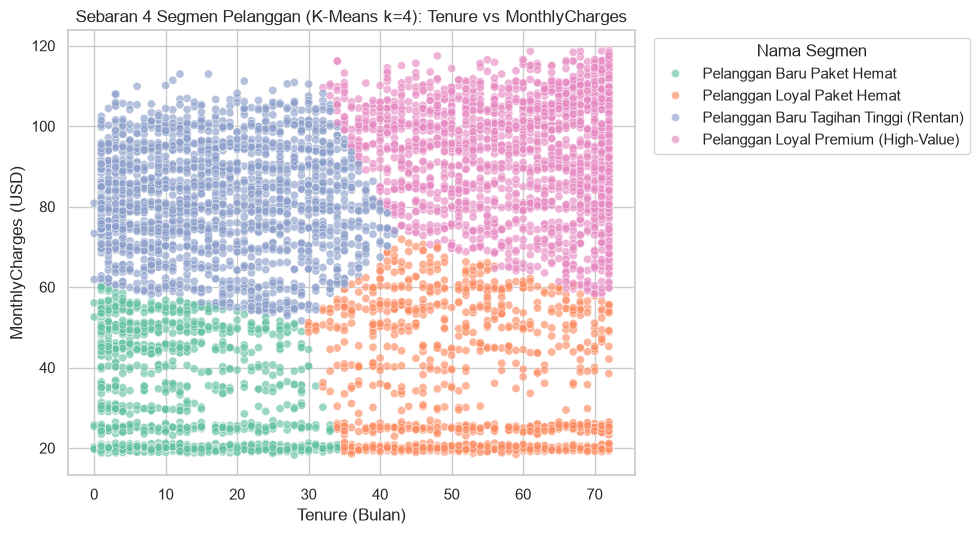

Hasil eksperimen clustering dan profil segmen tersimpan di data/outputs/


In [3]:
# Bangun Pipeline Clustering Terpilih (K-Means k=4)
selected_cluster_pipe = Pipeline([
    ('preprocessor', cluster_preprocessor),
    ('model', KMeans(n_clusters=4, random_state=SEED, n_init=10))
])

df['segment_id'] = selected_cluster_pipe.fit_predict(X_cluster)

# Hitung profil per segmen (termasuk komposisi Churn historis SETELAH klaster terbentuk)
seg_profile = df.groupby('segment_id').agg(
    Jumlah_Pelanggan=('customerID', 'count'),
    Tenure_Mean=('tenure', 'mean'),
    MonthlyCharges_Mean=('MonthlyCharges', 'mean'),
    TotalCharges_Mean=('TotalCharges', 'mean'),
    Churn_Yes_Count=('Churn', lambda s: int((s == 'Yes').sum()))
).reset_index()

seg_profile['Proporsi_Populasi (%)'] = (seg_profile['Jumlah_Pelanggan'] / len(df) * 100).round(2)
seg_profile['Historical_Churn_Rate (%)'] = (seg_profile['Churn_Yes_Count'] / seg_profile['Jumlah_Pelanggan'] * 100).round(2)

# Beri nama segmen secara otomatis berdasarkan karakteristik tenure & tagihan bulanan
median_tenure = seg_profile['Tenure_Mean'].median()
median_mc = seg_profile['MonthlyCharges_Mean'].median()

segment_name_map = {}
for _, row in seg_profile.iterrows():
    sid = int(row['segment_id'])
    is_loyal = row['Tenure_Mean'] >= median_tenure
    is_high_bill = row['MonthlyCharges_Mean'] >= median_mc
    if not is_loyal and is_high_bill:
        name = 'Pelanggan Baru Tagihan Tinggi (Rentan)'
    elif not is_loyal and not is_high_bill:
        name = 'Pelanggan Baru Paket Hemat'
    elif is_loyal and is_high_bill:
        name = 'Pelanggan Loyal Premium (High-Value)'
    else:
        name = 'Pelanggan Loyal Paket Hemat'
    segment_name_map[sid] = name

seg_profile['segment_name'] = seg_profile['segment_id'].map(segment_name_map)
display(seg_profile.round(2))

# Visualisasi Segmen (Tenure vs MonthlyCharges)
df['segment_name'] = df['segment_id'].map(segment_name_map)
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.scatterplot(
    data=df, x='tenure', y='MonthlyCharges', hue='segment_name',
    alpha=0.65, s=35, ax=ax
)
ax.set_title('Sebaran 4 Segmen Pelanggan (K-Means k=4): Tenure vs MonthlyCharges')
ax.set_xlabel('Tenure (Bulan)')
ax.set_ylabel('MonthlyCharges (USD)')
ax.legend(title='Nama Segmen', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Simpan tabel eksperimen dan profil segmen ke data/outputs/
df_cluster_exp.to_csv(OUTPUT_DIR / 'clustering_results.csv', index=False)
seg_profile.to_csv(OUTPUT_DIR / 'segment_profiles.csv', index=False)
print('Hasil eksperimen clustering dan profil segmen tersimpan di data/outputs/')